# 이거 내 이모지야 / これ、私の絵文字

**일본어 감정 기반 이모지 번역기 · Japanese emotion → emoji · LoRA Fine-tuning**

일본어 문장을 입력하면 대표 감정을 분류하고,
그 감정에 연결한 이모지와 함께 문장을 보여주는 작은 도구를 만든다.

## 1. 선택 이유와 실험 설계

| 항목 | 선택 |
|---|---|
| 분야 / 태스크 | Language / 일본어 문장의 대표 감정 8종 분류 |
| Base model | `tohoku-nlp/bert-base-japanese-v3` |
| 데이터 | WRIME ver.1, Hugging Face 등록명 `shunk031/wrime` |
| 정답 구성 | 독자 3명의 평균 감정 강도 중 유일한 최댓값을 갖는 감정 |
| 이모지 | 감정과 이모지의 고정 대응표를 직접 정의 |
| 학습 방식 | BERT attention의 query/value에 LoRA 적용 + 새 분류 헤드 학습 |
| 평가 | 고정된 Test의 Accuracy, 보조 지표 Macro-F1 및 감정별 성능 |

BERT 규모의 모델은 큰 생성형 모델보다 실험을 단순하게 구성하기 좋고,
WRIME의 감정 주석을 활용하면 데이터를 직접 라벨링하지 않고도 재미있는 이모지 출력을 만들 수 있다.
이 과제의 모델은 분류 모델이므로 Instruction/Prompt는 사용하지 않는다.

**정답의 의미:** 원본 WRIME는 이모지 데이터가 아니라 감정 강도 데이터다.
본 실험은 이를 대표 감정 하나의 분류로 변환한다. 따라서 Accuracy는 **만들어진 대표 감정 정답과의 일치율**이며,
사용자가 선호하는 이모지를 맞히는 정확도를 직접 측정한 값은 아니다.

**라이선스·접근:** 모델은 Apache-2.0, WRIME 원본은 CC BY-NC-ND 4.0으로 표시되어 있다.
공개 자료를 수업 실험에 사용하고 원문·가공 데이터의 별도 재배포나 상용 배포는 하지 않는다.
데이터 원문을 노트북 파일에 내장하지 않고 실행 시 원본에서 불러온다.

출처: [모델 카드](https://huggingface.co/tohoku-nlp/bert-base-japanese-v3),
[WRIME 원본·라이선스](https://github.com/ids-cv/wrime),
[Hugging Face 데이터 카드](https://huggingface.co/datasets/shunk031/wrime),
[WRIME 논문](https://aclanthology.org/2021.naacl-main.169/).

In [1]:
TASK = "Language"
MODEL_ID = "tohoku-nlp/bert-base-japanese-v3"
MODEL_REVISION = "65243d6e5629b969c77309f217bd7b1a79d43c7e"
DATASET_ID = "shunk031/wrime"
DATA_REVISION = "0681109ab52711110a491f055133033a4e0aea9c"
DATA_URL = f"https://raw.githubusercontent.com/ids-cv/wrime/{DATA_REVISION}/wrime-ver1.tsv"
SEED = 42
OUTPUT_DIR = "./assignment_runs/my_emoji"

# Colab에서 부담을 줄이기 위한 시작 설정. 처음 실행 전에 정하고,
# Test 성능을 본 뒤 이 값을 바꾸며 최적화하지 않는다.
TRAIN_LIMIT = 6000  # None이면 정제한 Train 전체
MAX_LENGTH = 128
NUM_EPOCHS = 3
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 16
GRADIENT_ACCUMULATION_STEPS = 2
LEARNING_RATE = 3e-4

EMOTIONS = ["joy", "sadness", "anticipation", "surprise", "anger", "fear", "disgust", "trust"]
EMOTION_KO = ["기쁨", "슬픔", "기대", "놀람", "분노", "두려움", "혐오", "신뢰"]
EMOTION_JA = ["喜び", "悲しみ", "期待", "驚き", "怒り", "恐れ", "嫌悪", "信頼"]
EMOJIS = ["😄", "😢", "🤩", "😲", "😠", "😨", "😖", "🤝"]
ID2LABEL = dict(enumerate(EMOTIONS))
LABEL2ID = {label: i for i, label in ID2LABEL.items()}

## 2. 실행 환경

라이브러리 API 변화를 줄이기 위해 핵심 패키지 버전을 고정한다. 일본어 토큰화에는 `fugashi`와 `unidic-lite`를 사용한다.
PyTorch는 Colab의 GPU 빌드를 사용하며, 이 모델의 PyTorch 가중치 로딩을 위해 2.6 이상인지 확인한다.
기본 설정은 GPU 학습용이다. 메모리가 부족하면 **첫 전체 실행 전** batch size를 8로 줄일 수 있다.

In [2]:
%pip install -q "transformers==4.57.3" "datasets==4.4.1" "pyarrow==21.0.0" "peft==0.18.0" "accelerate==1.12.0" "huggingface_hub>=0.34,<1.0" "fugashi==1.5.2" "unidic-lite==1.0.8" "safetensors>=0.4.3" "scikit-learn>=1.3,<2" "ipywidgets>=8,<9" pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
bigframes 2.51.0 requires pyarrow>=23.0.1, but you have pyarrow 21.0.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.10.0 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import gc
import hashlib
import html
import importlib.metadata
import json
import platform
import re
import time
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display, clear_output
from packaging.version import Version
from datasets import Dataset, DatasetDict, load_dataset
from transformers import (
    AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
    Trainer, TrainingArguments, pipeline, set_seed,
)
from peft import LoraConfig, PeftModel, TaskType, get_peft_model
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

assert Version(torch.__version__.split("+")[0]) >= Version("2.6"), (
    "현재 PyTorch가 2.6 미만입니다. 최신 Colab GPU 런타임을 사용하거나 "
    "PyTorch를 GPU 환경에 맞게 업데이트한 뒤 세션을 재시작하세요."
)
assert torch.cuda.is_available(), "Colab에서 런타임 유형을 GPU로 바꾼 뒤 다시 실행하세요."
set_seed(SEED)
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
print("Python:", platform.python_version())
print("Platform:", platform.platform())
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
VERSIONS = {
    name: importlib.metadata.version(name)
    for name in ["torch", "transformers", "datasets", "pyarrow", "peft", "accelerate", "huggingface_hub", "numpy", "pandas", "scikit-learn", "fugashi", "unidic-lite"]
}
display(pd.DataFrame.from_dict(VERSIONS, orient="index", columns=["version"]))
display(pd.DataFrame({"label": EMOTIONS, "한국어": EMOTION_KO, "日本語": EMOTION_JA, "emoji": EMOJIS}))

Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
GPU: Tesla T4
GPU memory (GiB): 14.56


,version
torch,2.14.1+cu130
transformers,4.57.3
datasets,4.4.1
pyarrow,21.0.0
peft,0.18.0
accelerate,1.12.0
huggingface_hub,0.36.2
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1


,label,한국어,日本語,emoji
0,joy,기쁨,喜び,😄
1,sadness,슬픔,悲しみ,😢
2,anticipation,기대,期待,🤩
3,surprise,놀람,驚き,😲
4,anger,분노,怒り,😠
5,fear,두려움,恐れ,😨
6,disgust,혐오,嫌悪,😖
7,trust,신뢰,信頼,🤝


## 3. 데이터 로딩과 정답 구성

`shunk031/wrime`의 기존 Python 로딩 스크립트에 의존하지 않고, 원본 저장소의 고정된 revision에서 TSV를
**`load_dataset("csv", delimiter="\t")`**로 읽는다. 원본의 `train/dev/test`를 `train/validation/test`에 대응시킨다.
원본은 작성자별로 분할되어 있으므로 새 무작위 분할을 만들지 않는다.

입력은 `Sentence`만 사용한다. `UserID`, 원본 감정 점수, 정답은 모델 입력에 넣지 않는다.
각 감정의 `Avg. Readers_*`를 비교해 **유일한 최고 강도가 양수인 문장만** 남긴다.
이 필터는 전체 데이터에 사전에 정한 동일 규칙으로 적용한다.

In [4]:
def prepare_splits(data, seed=SEED):
    splits = DatasetDict({"train": data}) if isinstance(data, Dataset) else DatasetDict(data)
    if "train" not in splits:
        raise ValueError("학습용 분할의 이름을 train으로 지정하세요.")
    if "test" not in splits:
        split = splits["train"].train_test_split(test_size=0.1, seed=seed)
        splits["train"], splits["test"] = split["train"], split["test"]
        validation_ratio = 1 / 9
    else:
        validation_ratio = 0.1
    if "validation" not in splits:
        split = splits["train"].train_test_split(test_size=validation_ratio, seed=seed)
        splits["train"], splits["validation"] = split["train"], split["test"]
    return DatasetDict({name: splits[name] for name in ("train", "validation", "test")})

In [5]:
AVERAGE_COLUMNS = [f"Avg. Readers_{emotion.title()}" for emotion in EMOTIONS]

def load_data():
    downloaded = load_dataset("csv", data_files={"source": DATA_URL}, delimiter="\t")["source"]
    expected = ["Sentence", "UserID", "Train/Dev/Test", *AVERAGE_COLUMNS]
    missing = set(expected) - set(downloaded.column_names)
    assert not missing, f"원본 열을 확인하세요: {missing}"
    source_df = downloaded.to_pandas()
    source_df["source_row"] = np.arange(len(source_df))
    print("원본 전체:", len(source_df))
    print("원본 열:", downloaded.column_names)
    display(source_df[["Sentence", "UserID", "Train/Dev/Test", *AVERAGE_COLUMNS]].head(3))
    name_map = {"train": "train", "dev": "validation", "test": "test"}
    assert set(source_df["Train/Dev/Test"]) == set(name_map)
    return DatasetDict({
        target: Dataset.from_pandas(
            source_df.loc[source_df["Train/Dev/Test"] == original].reset_index(drop=True),
            preserve_index=False,
        )
        for original, target in name_map.items()
    })

original = prepare_splits(load_data())
display(pd.DataFrame({"split": list(original), "original_rows": [len(original[s]) for s in original]}))

def make_emotion_label(example):
    scores = np.asarray([example[c] for c in AVERAGE_COLUMNS], dtype=float)
    sentence = str(example["Sentence"]).strip() if example["Sentence"] is not None else ""
    valid = bool(np.isfinite(scores).all() and sentence)
    top = float(scores.max()) if valid else 0.0
    winners = np.flatnonzero(np.isclose(scores, top, rtol=0, atol=1e-8)) if valid else []
    keep = bool(valid and top > 0 and len(winners) == 1)
    reason = "kept" if keep else ("empty_or_invalid" if not valid else "all_zero" if top <= 0 else "tied_max")
    key = re.sub(r"\s+", "", unicodedata.normalize("NFKC", sentence))
    return {
        "text": sentence,
        "labels": int(winners[0]) if keep else -1,
        "keep": keep,
        "filter_reason": reason,
        "dedup_key": key,
        "sample_id": f"wrime-v1-{int(example['source_row']):05d}",
        "user_id": str(example["UserID"]),
    }

labeled = original.map(make_emotion_label, desc="대표 감정 정답 생성")
filter_report = pd.DataFrame({
    name: pd.Series(labeled[name]["filter_reason"]).value_counts()
    for name in labeled
}).fillna(0).astype(int)
display(filter_report)
cleaned = DatasetDict({name: split.filter(lambda row: row["keep"], desc=f"{name}: 모호한 정답 제외")
                       for name, split in labeled.items()})

Generating source split: 0 examples [00:00, ? examples/s]

원본 전체: 43200
원본 열: ['Sentence', 'UserID', 'Datetime', 'Train/Dev/Test', 'Writer_Joy', 'Writer_Sadness', 'Writer_Anticipation', 'Writer_Surprise', 'Writer_Anger', 'Writer_Fear', 'Writer_Disgust', 'Writer_Trust', 'Reader1_Joy', 'Reader1_Sadness', 'Reader1_Anticipation', 'Reader1_Surprise', 'Reader1_Anger', 'Reader1_Fear', 'Reader1_Disgust', 'Reader1_Trust', 'Reader2_Joy', 'Reader2_Sadness', 'Reader2_Anticipation', 'Reader2_Surprise', 'Reader2_Anger', 'Reader2_Fear', 'Reader2_Disgust', 'Reader2_Trust', 'Reader3_Joy', 'Reader3_Sadness', 'Reader3_Anticipation', 'Reader3_Surprise', 'Reader3_Anger', 'Reader3_Fear', 'Reader3_Disgust', 'Reader3_Trust', 'Avg. Readers_Joy', 'Avg. Readers_Sadness', 'Avg. Readers_Anticipation', 'Avg. Readers_Surprise', 'Avg. Readers_Anger', 'Avg. Readers_Fear', 'Avg. Readers_Disgust', 'Avg. Readers_Trust']


,Sentence,UserID,Train/Dev/Test,Avg. Readers_Joy,Avg. Readers_Sadness,Avg. Readers_Anticipation,Avg. Readers_Surprise,Avg. Readers_Anger,Avg. Readers_Fear,Avg. Readers_Disgust,Avg. Readers_Trust
0,ぼけっとしてたらこんな時間｡チャリあるから食べにでたいのに…,1,train,0,2,0,0,0,0,0,0
1,今日の月も白くて明るい。昨日より雲が少なくてキレイな? と立ち止まる帰り道｡チャリなし生活も...,1,train,1,0,0,2,0,0,0,0
2,早寝するつもりが飲み物がなくなりコンビニへ｡ん､今日、風が涼しいな。,1,train,0,0,0,1,0,0,0,0


,split,original_rows
0,train,40000
1,validation,1200
2,test,2000


대표 감정 정답 생성:   0%|          | 0/40000 [00:00<?, ? examples/s]

대표 감정 정답 생성:   0%|          | 0/1200 [00:00<?, ? examples/s]

대표 감정 정답 생성:   0%|          | 0/2000 [00:00<?, ? examples/s]

,train,validation,test
kept,27173,787,1398
tied_max,10426,320,507
all_zero,2401,93,95


train: 모호한 정답 제외:   0%|          | 0/40000 [00:00<?, ? examples/s]

validation: 모호한 정답 제외:   0%|          | 0/1200 [00:00<?, ? examples/s]

test: 모호한 정답 제외:   0%|          | 0/2000 [00:00<?, ? examples/s]

### 중복·작성자 누출 확인과 사용할 데이터 수

정규화한 문장을 기준으로 같은 분할 안의 중복은 첫 문장만 남긴다.
분할 간 동일 문장이 있으면 **Test를 우선 유지하고**, Validation에서는 Test 중복을,
Train에서는 Validation/Test 중복을 제거한다. 문장을 다른 분할로 옮기지는 않는다.
이는 성능에 따른 선택이 아닌 사전에 정한 중복 정리 규칙이다.

Train만 기본 6,000개로 비례 층화 추출한다. 정제한 Validation/Test는 전체를 사용한다.
희소 감정의 성능을 볼 수 있도록 감정별 개수와 보조 지표도 출력한다.

In [6]:
dedup_report = []
seen_in_higher_priority_split = set()
deduplicated = {}
for name in ("test", "validation", "train"):
    split = cleaned[name]
    keys = split["dedup_key"]
    local_seen, keep_indices = set(), []
    within_dropped = cross_dropped = 0
    for i, key in enumerate(keys):
        if key in local_seen:
            within_dropped += 1
        elif key in seen_in_higher_priority_split:
            cross_dropped += 1
        else:
            keep_indices.append(i)
        local_seen.add(key)
    deduplicated[name] = split.select(keep_indices)
    seen_in_higher_priority_split.update(deduplicated[name]["dedup_key"])
    dedup_report.append({"split": name, "within_removed": within_dropped,
                         "cross_removed": cross_dropped, "remaining": len(keep_indices)})
display(pd.DataFrame(dedup_report))
raw = DatasetDict({name: deduplicated[name] for name in ("train", "validation", "test")})

if TRAIN_LIMIT is not None and len(raw["train"]) > TRAIN_LIMIT:
    selected, _ = train_test_split(
        np.arange(len(raw["train"])), train_size=TRAIN_LIMIT, random_state=SEED,
        stratify=raw["train"]["labels"],
    )
    raw["train"] = raw["train"].select(sorted(selected.tolist()))

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    text_overlap = set(raw[a]["dedup_key"]) & set(raw[b]["dedup_key"])
    user_overlap = set(raw[a]["user_id"]) & set(raw[b]["user_id"])
    print(f"{a} / {b}: 문장 중복 {len(text_overlap)}, 작성자 겹침 {len(user_overlap)}")
    assert not text_overlap and not user_overlap, "문장 또는 작성자 누출이 있습니다."

counts = pd.DataFrame({
    name: pd.Series(raw[name]["labels"]).value_counts().reindex(range(8), fill_value=0)
    for name in raw
})
counts.index = [f"{EMOJIS[i]} {EMOTIONS[i]}" for i in range(8)]
display(counts)
assert (counts > 0).all().all(), "분할에서 빠진 감정이 있습니다. 데이터 준비 규칙을 확인하세요."
assert len(raw["test"]) >= 5
print("최종 크기:", {name: len(split) for name, split in raw.items()})

def test_signature(test_data):
    content = list(zip(test_data["sample_id"], test_data["text"], test_data["labels"]))
    return hashlib.sha256(json.dumps(content, ensure_ascii=False).encode("utf-8")).hexdigest()

TEST_SIGNATURE = test_signature(raw["test"])
print("고정 Test SHA-256:", TEST_SIGNATURE)
print("Test는 학습·하이퍼파라미터 선택에 사용하지 않습니다.")

# JSON 직렬화 및 데이터 메모리를 줄이기 위해 필요한 열만 유지한다.
retained_columns = ["sample_id", "text", "labels", "user_id"]
raw = DatasetDict({name: split.select_columns(retained_columns) for name, split in raw.items()})
del original, labeled, cleaned, deduplicated
gc.collect()
display(raw["train"].select(range(5)).to_pandas())

,split,within_removed,cross_removed,remaining
0,test,1,0,1397
1,validation,0,0,787
2,train,110,1,27062


train / validation: 문장 중복 0, 작성자 겹침 0
train / test: 문장 중복 0, 작성자 겹침 0
validation / test: 문장 중복 0, 작성자 겹침 0


,train,validation,test
😄 joy,1403,216,329
😢 sadness,1027,115,210
🤩 anticipation,1590,235,441
😲 surprise,885,114,132
😠 anger,47,3,7
😨 fear,658,72,172
😖 disgust,365,28,99
🤝 trust,25,4,7


최종 크기: {'train': 6000, 'validation': 787, 'test': 1397}
고정 Test SHA-256: ff783418ab6b92226d1c10866850da2a5c0477d9409ac64cfda6e979b8e094e0
Test는 학습·하이퍼파라미터 선택에 사용하지 않습니다.


,sample_id,text,labels,user_id
0,wrime-v1-00009,最近アップにしていたので気づかなかったけど、ちゃんとブローしたらモテキ小宮山夏樹(後期)に似...,2,1
1,wrime-v1-00011,COWCOWヨシ君の顔色が最近ずっと悪い。病気ちゃうん?心配やわ。,5,1
2,wrime-v1-00015,雨…（笑）,3,1
3,wrime-v1-00022,天地明察みたいな?おもろいんかな?,2,1
4,wrime-v1-00031,落語…どしよかな…それか映画いこかな。,2,1


## 4. 모델과 전처리

일본어 BERT를 `AutoModelForSequenceClassification`으로 불러와 **8개 출력의 분류 헤드를 새로 초기화**한다.
기존 체크포인트의 MLM/NSP 헤드가 사용되지 않고 `classifier`가 새로 생성된다는 안내는 예상된 동작이다.
학습 전 기준값은 이 새 헤드를 학습하지 않은 상태의 성능이다.

최대 길이 128, 오른쪽 truncation, 배치 내 동적 padding을 사용한다.
학습 시 collator와 추론 시 pipeline 모두 동일 tokenizer와 길이 설정을 사용한다.
원문 이모지·문장부호는 유지하므로 모델이 이러한 단서에 의존할 수 있다는 점을 한계로 기록한다.

In [7]:
def load_model_and_processor():
    set_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    tokenizer.truncation_side = "right"
    tokenizer.padding_side = "right"
    classifier = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION,
        num_labels=len(EMOTIONS), id2label=ID2LABEL, label2id=LABEL2ID,
        attn_implementation="eager",
    )
    classifier.config.problem_type = "single_label_classification"
    return classifier, tokenizer

model, processor = load_model_and_processor()

def preprocess(example):
    tokens = processor(example["text"], truncation=True, max_length=MAX_LENGTH, padding=False)
    tokens["labels"] = int(example["labels"])
    return tokens

prepared = raw.map(preprocess, remove_columns=raw["train"].column_names, desc="일본어 토큰화")
display(prepared["train"][0])
print("Tokenizer:", type(processor).__name__)
print("새 분류 헤드:", model.classifier)
print("평가 설정:", {"max_length": MAX_LENGTH, "batch_size": EVAL_BATCH_SIZE,
                       "padding": "longest in batch", "truncation_side": processor.truncation_side})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/251 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/447M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/447M [00:00<?, ?B/s]

... (2 outputs left out)

일본어 토큰화:   0%|          | 0/787 [00:00<?, ? examples/s]

일본어 토큰화:   0%|          | 0/1397 [00:00<?, ? examples/s]

{'labels': 2,
 'input_ids': [2,
  16624,
  13546,
  461,
  441,
  456,
  422,
  449,
  464,
  457,
  28534,
  12581,
  449,
  18966,
  384,
  31586,
  22982,
  441,
  13123,
  570,
  15449,
  1829,
  8000,
  7189,
  1578,
  7900,
  23,
  14682,
  24,
  461,
  731,
  456,
  431,
  16328,
  385,
  12499,
  14200,
  17001,
  441,
  13123,
  13149,
  7087,
  441,
  7394,
  385,
  3],
 'token_type_ids': [0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0],
 'attention_mask': [1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1]}

Tokenizer: BertJapaneseTokenizer
새 분류 헤드: Linear(in_features=768, out_features=8, bias=True)
평가 설정: {'max_length': 128, 'batch_size': 16, 'padding': 'longest in batch', 'truncation_side': 'right'}


## 5. 학습 전 평가

`text-classification` pipeline으로 전체 고정 Test를 순서대로 추론한다.
정답과 예측을 동일한 정수 0~7로 변환한 뒤 제공된 Accuracy 코드를 사용한다.
Test를 일부 골라 평가에서 제외하지 않으며, 비교표용 예시는 같은 Test에서 학습 전에 고정한다.

In [8]:
def get_targets(test_data):
    return [int(label) for label in test_data["labels"]]

def make_pipeline(current_model):
    # get_base_model()은 활성 LoRA/분류 헤드가 주입된 BERT를 반환한다.
    # adapter를 끄거나 merge하지 않고 pipeline이 지원하는 원래 모델 클래스로 추론한다.
    inference_model = current_model.get_base_model() if isinstance(current_model, PeftModel) else current_model
    inference_model.eval()
    return pipeline("text-classification", model=inference_model, tokenizer=processor, device=0)

def predict_labels(current_model, processor, test_data):
    classifier = make_pipeline(current_model)
    with torch.inference_mode():
        outputs = classifier(
            list(test_data["text"]), top_k=1, truncation=True,
            max_length=MAX_LENGTH, padding=True, batch_size=EVAL_BATCH_SIZE,
        )
    predictions = []
    for output in outputs:
        best = output[0] if isinstance(output, list) else output
        predictions.append(LABEL2ID[best["label"]])
    return predictions

In [9]:
def accuracy(targets, predictions):
    if len(targets) == 0 or len(targets) != len(predictions):
        raise ValueError("정답과 예측은 길이가 같고 비어 있지 않아야 합니다.")
    return sum(a == b for a, b in zip(targets, predictions)) / len(targets)

def evaluate_model(current_model, processor, test_data):
    targets = get_targets(test_data)
    predictions = predict_labels(current_model, processor, test_data)
    if len(targets) != len(test_data):
        raise ValueError("Test의 모든 샘플에 대해 정답과 예측을 반환하세요.")
    metrics = {"accuracy": accuracy(targets, predictions)}
    table = pd.DataFrame({"sample_id": range(len(targets)), "target": targets,
                          "prediction": predictions})
    return metrics, table

In [10]:
assert test_signature(raw["test"]) == TEST_SIGNATURE
before_metrics, before = evaluate_model(model, processor, raw["test"])
before_metrics["macro_f1"] = float(f1_score(before["target"], before["prediction"], labels=list(range(8)), average="macro", zero_division=0))
majority_label = int(pd.Series(raw["train"]["labels"]).value_counts().idxmax())
majority_accuracy = accuracy(get_targets(raw["test"]), [majority_label] * len(raw["test"]))
print("学習前 / 학습 전:", before_metrics)
print(f"Train 최빈 감정만 예측하는 참고 기준: {EMOTIONS[majority_label]}, Accuracy={majority_accuracy:.4f}")

# 감정별 첫 샘플을 먼저 선택한 뒤 10개까지 채운다. 성능을 보고 고르지 않는다.
COMPARISON_INDICES = []
test_labels = list(raw["test"]["labels"])
for label in range(8):
    COMPARISON_INDICES.append(test_labels.index(label))
for index in range(len(raw["test"])):
    if index not in COMPARISON_INDICES:
        COMPARISON_INDICES.append(index)
    if len(COMPARISON_INDICES) >= 10:
        break

def label_text(label):
    label = int(label)
    return f"{EMOJIS[label]} {EMOTION_KO[label]} ({EMOTION_JA[label]})"

before_examples = pd.DataFrame({
    "입력 식별자": [raw["test"][i]["sample_id"] for i in COMPARISON_INDICES],
    "일본어 입력": [raw["test"][i]["text"] for i in COMPARISON_INDICES],
    "정답": [label_text(raw["test"][i]["labels"]) for i in COMPARISON_INDICES],
    "학습 전": [label_text(before.iloc[i]["prediction"]) for i in COMPARISON_INDICES],
})
display(before_examples)

Device set to use cuda:0


学習前 / 학습 전: {'accuracy': 0.1224051539012169, 'macro_f1': 0.07359876414119637}
Train 최빈 감정만 예측하는 참고 기준: anticipation, Accuracy=0.3157


,입력 식별자,일본어 입력,정답,학습 전
0,wrime-v1-24904,ハシが狂っていく様が儚げで見てて辛かったけど、なんか好き…,😄 기쁨 (喜び),😠 분노 (怒り)
1,wrime-v1-24903,あぁーテスト勉強(),😢 슬픔 (悲しみ),🤝 신뢰 (信頼)
2,wrime-v1-24905,明るいポップな曲も可愛いから好きだけど、しゃわげとか落ち着いてるけど華やかな、大人っぽい曲で...,🤩 기대 (期待),😨 두려움 (恐れ)
3,wrime-v1-24946,ちょ、やば、,😲 놀람 (驚き),😢 슬픔 (悲しみ)
4,wrime-v1-25413,この素晴らしい人材を逃してもっと悲しめ,😠 분노 (怒り),😠 분노 (怒り)
5,wrime-v1-24914,30分以上遅刻してるけど一応行く,😨 두려움 (恐れ),😠 분노 (怒り)
6,wrime-v1-24909,お腹空いた,😖 혐오 (嫌悪),🤝 신뢰 (信頼)
7,wrime-v1-27584,なんだかんだ母は偉大。,🤝 신뢰 (信頼),😨 두려움 (恐れ)
8,wrime-v1-24906,しゃわげ大好き人間なんだよね…,😄 기쁨 (喜び),😠 분노 (怒り)
9,wrime-v1-24907,かわ、かわぁ…！；；；；,😄 기쁨 (喜び),😠 분노 (怒り)


## 6. LoRA 설정과 학습 대상 확인

BERT attention의 `query`, `value` Linear 모듈을 확인한 뒤 Rank 8, alpha 16, dropout 0.1로 설정한다.
`modules_to_save=["classifier"]`로 **새 분류 헤드를 함께 학습·저장**한다.
본 실험에서 측정한 변화는 LoRA와 분류 헤드 학습의 결합 효과다.
Base BERT의 나머지 파라미터는 고정한다.

설정 근거: [PEFT LoRA 문서](https://huggingface.co/docs/peft/v0.18.0/en/package_reference/lora).

In [11]:
target_names = [name for name, module in model.named_modules()
                if isinstance(module, torch.nn.Linear) and name.split(".")[-1] in {"query", "value"}]
assert len(target_names) == 2 * model.config.num_hidden_layers
print("LoRA 대상 개수:", len(target_names))
print("\n".join(target_names))

def make_lora_config(model):
    return LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=8, lora_alpha=16, lora_dropout=0.1,
        target_modules=["query", "value"],
        bias="none", modules_to_save=["classifier"],
    )

lora_config = make_lora_config(model)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
trainable_rows = [{"parameter": name, "count": parameter.numel()}
                  for name, parameter in model.named_parameters() if parameter.requires_grad]
assert trainable_rows
assert all("lora_" in row["parameter"] or "classifier" in row["parameter"] for row in trainable_rows)
assert any("classifier" in row["parameter"] for row in trainable_rows)
TRAINABLE_PARAMETERS = sum(row["count"] for row in trainable_rows)
TOTAL_PARAMETERS = sum(p.numel() for p in model.parameters())
display(pd.DataFrame(trainable_rows))
print(f"학습 가능: {TRAINABLE_PARAMETERS:,} / 전체: {TOTAL_PARAMETERS:,} ({100*TRAINABLE_PARAMETERS/TOTAL_PARAMETERS:.3f}%)")

LoRA 대상 개수: 24
bert.encoder.layer.0.attention.self.query
bert.encoder.layer.0.attention.self.value
bert.encoder.layer.1.attention.self.query
bert.encoder.layer.1.attention.self.value
bert.encoder.layer.2.attention.self.query
bert.encoder.layer.2.attention.self.value
bert.encoder.layer.3.attention.self.query
bert.encoder.layer.3.attention.self.value
bert.encoder.layer.4.attention.self.query
bert.encoder.layer.4.attention.self.value
bert.encoder.layer.5.attention.self.query
bert.encoder.layer.5.attention.self.value
bert.encoder.layer.6.attention.self.query
bert.encoder.layer.6.attention.self.value
bert.encoder.layer.7.attention.self.query
bert.encoder.layer.7.attention.self.value
bert.encoder.layer.8.attention.self.query
bert.encoder.layer.8.attention.self.value
bert.encoder.layer.9.attention.self.query
bert.encoder.layer.9.attention.self.value
bert.encoder.layer.10.attention.self.query
bert.encoder.layer.10.attention.self.value
bert.encoder.layer.11.attention.self.query
bert.encoder.lay

,parameter,count
0,base_model.model.bert.encoder.layer.0.attentio...,6144
1,base_model.model.bert.encoder.layer.0.attentio...,6144
2,base_model.model.bert.encoder.layer.0.attentio...,6144
3,base_model.model.bert.encoder.layer.0.attentio...,6144
4,base_model.model.bert.encoder.layer.1.attentio...,6144
5,base_model.model.bert.encoder.layer.1.attentio...,6144
6,base_model.model.bert.encoder.layer.1.attentio...,6144
7,base_model.model.bert.encoder.layer.1.attentio...,6144
8,base_model.model.bert.encoder.layer.2.attentio...,6144
9,base_model.model.bert.encoder.layer.2.attentio...,6144


학습 가능: 301,064 / 전체: 111,514,384 (0.270%)


## 7. 학습과 Validation

Cross-entropy로 학습하며, epoch마다 Validation Accuracy와 Macro-F1을 출력한다.
Validation Macro-F1이 가장 높은 checkpoint를 최종 모델로 선택한다.
Test는 Trainer에 전달하지 않는다. 희소 클래스가 있어 Accuracy와 Macro-F1이 다르게 움직일 수 있다.
추가 가중 손실·하이퍼파라미터 탐색은 수행하지 않는다.

,epochs,train_rows,batch_size,effective_batch_size,learning_rate,max_length,precision,best_model_metric
0,3,6000,16,32,0.0003,128,bf16,Validation Macro-F1


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.305200,1.050229,0.622618,0.344854
2,1.084500,0.947716,0.675985,0.415698
3,1.040900,0.924568,0.668361,0.415273


학습 소요 시간(초): 292.0
선택된 checkpoint: ./assignment_runs/my_emoji/checkpoint-376
최고 Validation Macro-F1: 0.41569843530274664


,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss,epoch
0,290.0101,62.067,1.945,7.703662e+14,1.253817,3.0


,eval_loss,eval_accuracy,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch
0,0.947716,0.675985,0.415698,4.2266,186.2,11.83,3.0


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,2.0807,3.508860,0.000126,0.133333,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.8483,3.742285,0.000258,0.266667,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.7216,2.798818,0.000290,0.400000,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.6509,2.333945,0.000275,0.533333,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.4388,3.796910,0.000260,0.666667,125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1.3077,3.183391,0.000246,0.800000,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1.3052,3.008299,0.000231,0.933333,175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,1.000000,188,1.050229,0.622618,0.344854,4.2925,183.344,11.648,NaN,NaN,NaN,NaN,NaN
8,1.2331,3.692714,0.000216,1.064000,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1.1439,2.858356,0.000201,1.197333,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


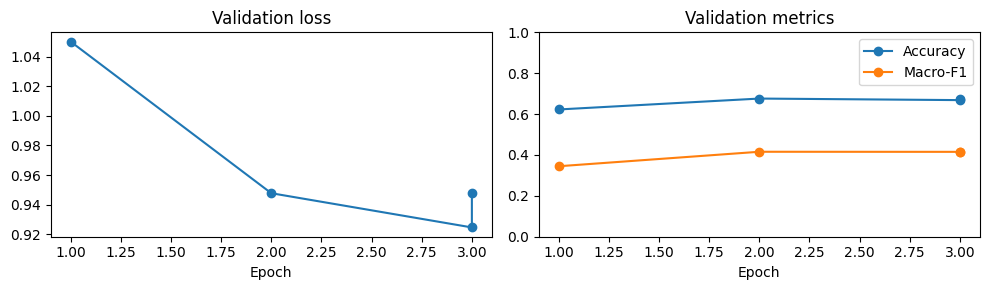

In [12]:
def compute_metrics(eval_prediction):
    logits, targets = eval_prediction
    if isinstance(logits, tuple):
        logits = logits[0]
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy(targets.tolist(), predictions.tolist()),
        "macro_f1": float(f1_score(targets, predictions, labels=list(range(8)), average="macro", zero_division=0)),
    }

def make_trainer(model, processor, train_data, validation_data):
    use_bf16 = torch.cuda.is_bf16_supported()
    arguments = TrainingArguments(
        output_dir=OUTPUT_DIR,
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        learning_rate=LEARNING_RATE,
        weight_decay=0.01,
        warmup_ratio=0.1,
        eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1", greater_is_better=True,
        save_total_limit=1, logging_steps=25,
        bf16=use_bf16, fp16=not use_bf16,
        optim="adamw_torch", report_to="none",
        seed=SEED, data_seed=SEED,
        dataloader_num_workers=0,
        label_names=["labels"], remove_unused_columns=True,
    )
    return Trainer(
        model=model, args=arguments,
        train_dataset=train_data, eval_dataset=validation_data,
        processing_class=processor,
        data_collator=DataCollatorWithPadding(tokenizer=processor, pad_to_multiple_of=8),
        compute_metrics=compute_metrics,
    )

trainer = make_trainer(model, processor, prepared["train"], prepared["validation"])
display(pd.DataFrame([{
    "epochs": NUM_EPOCHS, "train_rows": len(prepared["train"]),
    "batch_size": TRAIN_BATCH_SIZE, "effective_batch_size": TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS,
    "learning_rate": LEARNING_RATE, "max_length": MAX_LENGTH,
    "precision": "bf16" if trainer.args.bf16 else "fp16", "best_model_metric": "Validation Macro-F1",
}]))
started = time.perf_counter()
train_result = trainer.train()
TRAIN_SECONDS = time.perf_counter() - started
model = trainer.model
print("학습 소요 시간(초):", round(TRAIN_SECONDS, 1))
print("선택된 checkpoint:", trainer.state.best_model_checkpoint)
print("최고 Validation Macro-F1:", trainer.state.best_metric)
display(pd.DataFrame([train_result.metrics]))
validation_metrics = trainer.evaluate()
display(pd.DataFrame([validation_metrics]))
logs = pd.DataFrame(trainer.state.log_history)
display(logs)
epoch_metrics = logs.dropna(subset=["eval_loss"]) if "eval_loss" in logs else pd.DataFrame()
if not epoch_metrics.empty:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].plot(epoch_metrics["epoch"], epoch_metrics["eval_loss"], marker="o")
    axes[0].set(title="Validation loss", xlabel="Epoch")
    axes[1].plot(epoch_metrics["epoch"], epoch_metrics["eval_accuracy"], marker="o", label="Accuracy")
    axes[1].plot(epoch_metrics["epoch"], epoch_metrics["eval_macro_f1"], marker="o", label="Macro-F1")
    axes[1].set(title="Validation metrics", xlabel="Epoch", ylim=(0, 1))
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## 8. 학습 후 평가와 같은 Test의 비교표

학습 전과 동일한 데이터 지문·tokenizer·최대 길이·배치 크기·argmax 분류 조건을 사용한다.
아래 첫 비교표는 제공된 스켈레톤 코드를 사용하며, 이어서 학습 전에 고정한 10개 예시를 일본어와 이모지로 표시한다.

In [13]:
assert test_signature(raw["test"]) == TEST_SIGNATURE
after_metrics, after = evaluate_model(model, processor, raw["test"])
assert len(before) >= 5 and len(after) >= 5, "비교 샘플을 최소 5개 기록하세요."
assert before["sample_id"].is_unique and after["sample_id"].is_unique
assert before[["sample_id", "target"]].reset_index(drop=True).equals(
    after[["sample_id", "target"]].reset_index(drop=True)
), "학습 전후 동일한 샘플·순서·정답을 사용하세요."
comparison = before.rename(columns={"prediction": "before"}).merge(
    after[["sample_id", "prediction"]].rename(columns={"prediction": "after"}),
    on="sample_id", validate="one_to_one"
)
display(pd.DataFrame({"before": before_metrics, "after": after_metrics}))
display(comparison.head(10))

Device set to use cuda:0


,before,after
accuracy,0.122405,0.624911
macro_f1,0.073599,NaN


,sample_id,target,before,after
0,0,1,7,2
1,1,0,4,0
2,2,2,5,2
3,3,0,4,0
4,4,0,4,2
5,5,6,7,1
6,6,2,4,2
7,7,1,4,1
8,8,5,4,2
9,9,0,5,0


,학습 전,학습 후,변화 (후−전)
accuracy,0.122405,0.624911,0.502505
macro_f1,0.073599,0.384419,0.310820


,입력 식별자,일본어 입력,정답,학습 전,학습 후
0,wrime-v1-24904,ハシが狂っていく様が儚げで見てて辛かったけど、なんか好き…,😄 기쁨 (喜び),😠 분노 (怒り),😄 기쁨 (喜び)
1,wrime-v1-24903,あぁーテスト勉強(),😢 슬픔 (悲しみ),🤝 신뢰 (信頼),🤩 기대 (期待)
2,wrime-v1-24905,明るいポップな曲も可愛いから好きだけど、しゃわげとか落ち着いてるけど華やかな、大人っぽい曲で...,🤩 기대 (期待),😨 두려움 (恐れ),🤩 기대 (期待)
3,wrime-v1-24946,ちょ、やば、,😲 놀람 (驚き),😢 슬픔 (悲しみ),😄 기쁨 (喜び)
4,wrime-v1-25413,この素晴らしい人材を逃してもっと悲しめ,😠 분노 (怒り),😠 분노 (怒り),😢 슬픔 (悲しみ)
5,wrime-v1-24914,30分以上遅刻してるけど一応行く,😨 두려움 (恐れ),😠 분노 (怒り),🤩 기대 (期待)
6,wrime-v1-24909,お腹空いた,😖 혐오 (嫌悪),🤝 신뢰 (信頼),😢 슬픔 (悲しみ)
7,wrime-v1-27584,なんだかんだ母は偉大。,🤝 신뢰 (信頼),😨 두려움 (恐れ),😄 기쁨 (喜び)
8,wrime-v1-24906,しゃわげ大好き人間なんだよね…,😄 기쁨 (喜び),😠 분노 (怒り),😄 기쁨 (喜び)
9,wrime-v1-24907,かわ、かわぁ…！；；；；,😄 기쁨 (喜び),😠 분노 (怒り),🤩 기대 (期待)


,precision,recall,f1-score,support
joy,0.680412,0.802432,0.736402,329.000000
sadness,0.489437,0.661905,0.562753,210.000000
anticipation,0.738947,0.795918,0.766376,441.000000
surprise,0.403727,0.492424,0.443686,132.000000
anger,0.000000,0.000000,0.000000,7.000000
fear,0.597015,0.232558,0.334728,172.000000
disgust,0.636364,0.141414,0.231405,99.000000
trust,0.000000,0.000000,0.000000,7.000000
accuracy,0.624911,0.624911,0.624911,0.624911
macro avg,0.443238,0.390831,0.384419,1397.000000


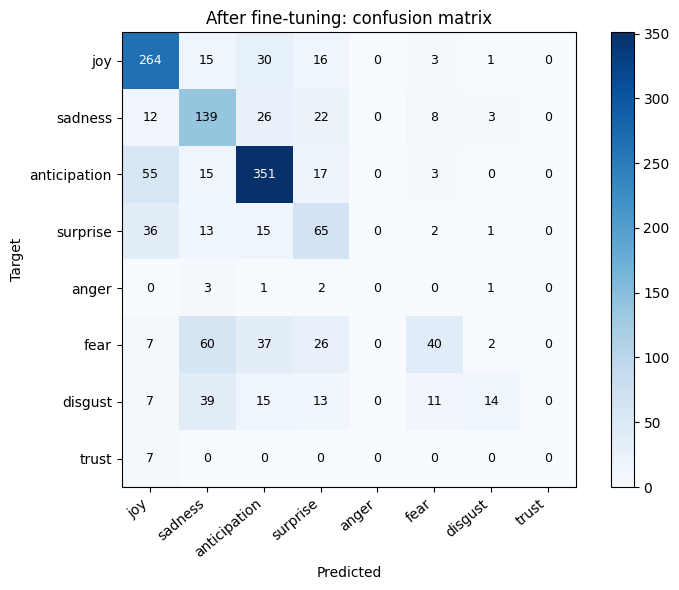

In [14]:
after_metrics["macro_f1"] = float(f1_score(after["target"], after["prediction"], labels=list(range(8)), average="macro", zero_division=0))
metric_table = pd.DataFrame({"학습 전": before_metrics, "학습 후": after_metrics})
metric_table["변화 (후−전)"] = metric_table["학습 후"] - metric_table["학습 전"]
display(metric_table)

emoji_comparison = before_examples.copy()
emoji_comparison["학습 후"] = [label_text(after.iloc[i]["prediction"]) for i in COMPARISON_INDICES]
display(emoji_comparison)

report = classification_report(
    after["target"], after["prediction"], labels=list(range(8)),
    target_names=EMOTIONS, output_dict=True, zero_division=0,
)
display(pd.DataFrame(report).T)
matrix = confusion_matrix(after["target"], after["prediction"], labels=list(range(8)))
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(matrix, cmap="Blues")
ax.set(xticks=range(8), yticks=range(8), xticklabels=EMOTIONS, yticklabels=EMOTIONS,
       xlabel="Predicted", ylabel="Target", title="After fine-tuning: confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
for i in range(8):
    for j in range(8):
        ax.text(j, i, str(matrix[i, j]), ha="center", va="center",
                color="white" if matrix[i, j] > matrix.max() / 2 else "black", fontsize=9)
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## 9. 실패 사례와 결과 해석

아래 수치와 사례는 실제 실행 결과에서 생성된다. 결과를 본 뒤 필요하면 마지막 개인 해석 칸에 관찰을 덧붙인다.
성능 향상 여부와 관계없이 결과를 그대로 보고한다.

In [15]:
failed_indices = after.index[after["target"] != after["prediction"]].tolist()
fixed_indices = [i for i in range(len(after)) if before.iloc[i]["prediction"] != after.iloc[i]["target"]
                 and after.iloc[i]["prediction"] == after.iloc[i]["target"]]
regressed_indices = [i for i in range(len(after)) if before.iloc[i]["prediction"] == after.iloc[i]["target"]
                     and after.iloc[i]["prediction"] != after.iloc[i]["target"]]

def case_table(indices):
    return pd.DataFrame([{
        "입력 식별자": raw["test"][i]["sample_id"], "일본어 입력": raw["test"][i]["text"],
        "정답": label_text(after.iloc[i]["target"]),
        "학습 전": label_text(before.iloc[i]["prediction"]),
        "학습 후": label_text(after.iloc[i]["prediction"]),
    } for i in indices])

print(f"학습 후 오답 {len(failed_indices)}개 / 개선된 예측 {len(fixed_indices)}개 / 새로 틀린 예측 {len(regressed_indices)}개")
print("학습 후 실패 사례 (최대 5개)")
display(case_table(failed_indices[:5]))
print("개선 사례 (최대 3개)")
display(case_table(fixed_indices[:3]))
print("새로 틀린 사례 (최대 3개)")
display(case_table(regressed_indices[:3]))

delta = after_metrics["accuracy"] - before_metrics["accuracy"]
direction = "상승" if delta > 0 else "하락" if delta < 0 else "동일"
f1_delta = after_metrics["macro_f1"] - before_metrics["macro_f1"]
display(Markdown(
    f"**실행 결과 해석**\n\n"
    f"고정 Test {len(raw['test']):,}개에서 Accuracy는 "
    f"{before_metrics['accuracy']:.4f} → {after_metrics['accuracy']:.4f}로 "
    f"{direction}했다(변화 {delta*100:+.2f}%p). "
    f"Macro-F1은 {before_metrics['macro_f1']:.4f} → {after_metrics['macro_f1']:.4f} "
    f"(변화 {f1_delta:+.4f})였다. "
    f"이 결과는 새로 초기화한 분류 헤드와 LoRA를 함께 학습한 결과다. "
    f"LoRA만의 인과적 효과를 분리하려면 분류 헤드만 학습하는 별도 대조 실험이 필요하다."
))

# 가장 많이 혼동한 서로 다른 감정 쌍을 실제 결과로 표시한다.
off_diagonal = matrix.copy()
np.fill_diagonal(off_diagonal, 0)
if off_diagonal.max() > 0:
    target_i, prediction_i = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(f"가장 많은 오분류 방향: {EMOTIONS[target_i]} → {EMOTIONS[prediction_i]} ({off_diagonal.max()}개)")

학습 후 오답 524개 / 개선된 예측 771개 / 새로 틀린 예측 69개
학습 후 실패 사례 (최대 5개)


,입력 식별자,일본어 입력,정답,학습 전,학습 후
0,wrime-v1-24903,あぁーテスト勉強(),😢 슬픔 (悲しみ),🤝 신뢰 (信頼),🤩 기대 (期待)
1,wrime-v1-24907,かわ、かわぁ…！；；；；,😄 기쁨 (喜び),😠 분노 (怒り),🤩 기대 (期待)
2,wrime-v1-24909,お腹空いた,😖 혐오 (嫌悪),🤝 신뢰 (信頼),😢 슬픔 (悲しみ)
3,wrime-v1-24914,30分以上遅刻してるけど一応行く,😨 두려움 (恐れ),😠 분노 (怒り),🤩 기대 (期待)
4,wrime-v1-24922,高い鼻とぱっちりな目に生まれたい人生だった,😢 슬픔 (悲しみ),😠 분노 (怒り),🤩 기대 (期待)


개선 사례 (최대 3개)


,입력 식별자,일본어 입력,정답,학습 전,학습 후
0,wrime-v1-24904,ハシが狂っていく様が儚げで見てて辛かったけど、なんか好き…,😄 기쁨 (喜び),😠 분노 (怒り),😄 기쁨 (喜び)
1,wrime-v1-24905,明るいポップな曲も可愛いから好きだけど、しゃわげとか落ち着いてるけど華やかな、大人っぽい曲で...,🤩 기대 (期待),😨 두려움 (恐れ),🤩 기대 (期待)
2,wrime-v1-24906,しゃわげ大好き人間なんだよね…,😄 기쁨 (喜び),😠 분노 (怒り),😄 기쁨 (喜び)


새로 틀린 사례 (최대 3개)


,입력 식별자,일본어 입력,정답,학습 전,학습 후
0,wrime-v1-25008,あかんでド緊張やで,😨 두려움 (恐れ),😨 두려움 (恐れ),😢 슬픔 (悲しみ)
1,wrime-v1-25069,あと「ずっと君を守るよ?」の所で毎回死ぬよね(),😄 기쁨 (喜び),😄 기쁨 (喜び),😨 두려움 (恐れ)
2,wrime-v1-25359,美容院2ヶ月行ってないから、ギャルみたいな髪色になってるわ,😨 두려움 (恐れ),😨 두려움 (恐れ),😲 놀람 (驚き)


**실행 결과 해석**

고정 Test 1,397개에서 Accuracy는 0.1224 → 0.6249로 상승했다(변화 +50.25%p). Macro-F1은 0.0736 → 0.3844 (변화 +0.3108)였다. 이 결과는 새로 초기화한 분류 헤드와 LoRA를 함께 학습한 결과다. LoRA만의 인과적 효과를 분리하려면 분류 헤드만 학습하는 별도 대조 실험이 필요하다.

가장 많은 오분류 방향: fear → sadness (60개)


### 한계와 개인 해석

- **정답 단순화:** 여러 감정이 공존하는 문장을 대표 감정 하나로 줄였다. 동점·감정 없음 문장을 제외했으므로 전체 일본어 문장에 대한 성능은 아니다.
- **클래스 불균형:** 분노·신뢰 등은 데이터가 적어 Accuracy만으로는 성능을 판단하기 어렵다. Macro-F1과 감정별 support/recall을 함께 확인한다.
- **주관성과 문맥:** 독자들의 평균 감정 주석이 작성자의 의도나 사용자가 원하는 이모지와 항상 같지는 않다. 반어·생략·문맥 의존 표현은 실패할 수 있다.
- **데이터 범위:** 과거 SNS 데이터와 일부 작성자를 기반으로 했으므로 취업 면접·업무 메일·요즘 표현에 그대로 일반화된다고 볼 수 없다.
- **입력 단서:** 원문에 있던 이모지·감탄부호가 남아 있어, 감정 단서가 없는 문장에서는 성능이 달라질 수 있다. 128토큰을 넘는 부분은 잘린다.
- **실험 범위:** 단일 seed·일부 Train·한 번의 학습 결과이며, 통계적 유의성이나 최적 설정을 주장하지 않는다.
- **개인 해석 — 실행 후 보완:** 위 실패 사례 중 한두 문장을 골라 실제 정답과 예측이 왜 달라 보이는지, 일본어 문맥을 읽고 덧붙인다.

## 10. Adapter·Tokenizer·설정 저장과 재로딩 확인

Adapter와 새 분류 헤드는 `save_pretrained`로 함께 저장한다.
Tokenizer, 모델 설정, 감정↔이모지 대응표, 실행 환경·분할·학습 설정도 같은 폴더에 저장한다.
아래 저장물은 Colab 내부 파일이며 별도 제출물은 아니다.
재로딩 검증은 **Validation 문장 3개**를 사용한다.

In [16]:
adapter_dir = Path(OUTPUT_DIR) / "adapter"
model.save_pretrained(adapter_dir)
processor.save_pretrained(adapter_dir)
model.config.save_pretrained(adapter_dir)

emoji_mapping = [{"id": i, "label": EMOTIONS[i], "ko": EMOTION_KO[i], "ja": EMOTION_JA[i], "emoji": EMOJIS[i]}
                 for i in range(8)]
manifest = {
    "title_ko": "이거 내 이모지야", "title_ja": "これ、私の絵文字。",
    "base_model": MODEL_ID, "model_revision": MODEL_REVISION,
    "dataset_id": DATASET_ID, "data_revision": DATA_REVISION, "data_url": DATA_URL,
    "data_license": "CC BY-NC-ND 4.0", "model_license": "Apache-2.0",
    "label_rule": "unique positive maximum of Avg. Readers_*; ties and all-zero excluded",
    "split_policy": "original writer-disjoint split; within/cross text dedup; stratified Train subset only",
    "split_sizes": {name: len(split) for name, split in raw.items()},
    "test_sha256": TEST_SIGNATURE, "seed": SEED, "max_length": MAX_LENGTH,
    "train_limit": TRAIN_LIMIT, "epochs": NUM_EPOCHS, "learning_rate": LEARNING_RATE,
    "train_batch_size": TRAIN_BATCH_SIZE, "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "eval_batch_size": EVAL_BATCH_SIZE, "lora_rank": 8, "lora_alpha": 16, "lora_dropout": 0.1,
    "target_modules": ["query", "value"], "modules_to_save": ["classifier"],
    "trainable_parameters": TRAINABLE_PARAMETERS, "total_parameters": TOTAL_PARAMETERS,
    "best_validation_macro_f1": trainer.state.best_metric,
    "before_metrics": before_metrics, "after_metrics": after_metrics,
    "versions": VERSIONS, "gpu": torch.cuda.get_device_name(0), "train_seconds": TRAIN_SECONDS,
}
for filename, data in [("emoji_mapping.json", emoji_mapping), ("experiment_config.json", manifest)]:
    (adapter_dir / filename).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")

from safetensors import safe_open
adapter_weights = adapter_dir / "adapter_model.safetensors"
assert adapter_weights.exists()
with safe_open(str(adapter_weights), framework="pt", device="cpu") as handle:
    saved_keys = list(handle.keys())
assert any("classifier" in key for key in saved_keys), "분류 헤드 저장을 확인하세요."
assert any("lora_" in key for key in saved_keys)
print("Base model:", MODEL_ID)
print("Model revision:", MODEL_REVISION)
print("저장 위치:", adapter_dir.resolve())
print("Adapter와 classifier 저장 확인: 통과")
display(pd.DataFrame([{"file": path.name, "KiB": round(path.stat().st_size / 1024, 2)}
                      for path in sorted(adapter_dir.iterdir()) if path.is_file()]))

# 원본과 재로딩 모델을 모두 CPU / float32 / eval로 맞춰 검증한다.
# Trainer/Accelerate의 mixed-precision forward wrapper를 우회하려고
# 활성 LoRA와 classifier가 주입된 실제 BERT를 직접 호출한다.
probe_texts = list(raw["validation"].select(range(3))["text"])
original_device = next(model.parameters()).device
reference_bert = model.get_base_model() if isinstance(model, PeftModel) else model
reload_model = None

try:
    reference_bert.to(device="cpu", dtype=torch.float32).eval()
    probe_inputs = processor(
        probe_texts, return_tensors="pt", padding=True,
        truncation=True, max_length=MAX_LENGTH,
    )
    with torch.inference_mode(), torch.autocast(device_type="cpu", enabled=False):
        expected_logits = reference_bert(**probe_inputs).logits.detach().clone()

    reload_tokenizer = AutoTokenizer.from_pretrained(adapter_dir)
    reload_base = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, num_labels=len(EMOTIONS),
        id2label=ID2LABEL, label2id=LABEL2ID, attn_implementation="eager",
    )
    reload_model = PeftModel.from_pretrained(reload_base, adapter_dir)
    reload_bert = reload_model.get_base_model().to(device="cpu", dtype=torch.float32).eval()
    reload_inputs = reload_tokenizer(
        probe_texts, return_tensors="pt", padding=True,
        truncation=True, max_length=MAX_LENGTH,
    )
    assert set(probe_inputs) == set(reload_inputs)
    assert all(torch.equal(probe_inputs[key], reload_inputs[key]) for key in probe_inputs), (
        "원본과 재로딩 Tokenizer의 입력이 다릅니다."
    )

    # 출력만 비교하기 전에 실제로 저장한 학습 가중치가 정확히 복원됐는지 확인한다.
    # classifier.original_module은 사용하지 않는 초기 헤드이므로 비교 대상에서 제외한다.
    def active_trainable_weights(bert):
        return {
            name: parameter.detach()
            for name, parameter in bert.named_parameters()
            if "lora_" in name or ("classifier" in name and "modules_to_save." in name)
        }

    reference_weights = active_trainable_weights(reference_bert)
    restored_weights = active_trainable_weights(reload_bert)
    assert reference_weights and set(reference_weights) == set(restored_weights), (
        "LoRA 또는 분류 헤드의 파라미터 이름이 다릅니다."
    )
    mismatched = [name for name in reference_weights
                  if not torch.equal(reference_weights[name], restored_weights[name])]
    assert not mismatched, f"저장 가중치 복원 불일치: {mismatched[:5]}"
    print(f"LoRA + classifier 가중치 {len(reference_weights)}개: 정확히 일치")

    with torch.inference_mode(), torch.autocast(device_type="cpu", enabled=False):
        restored_logits = reload_bert(**reload_inputs).logits.detach().clone()
    max_difference = float((expected_logits - restored_logits).abs().max())
    same_predictions = torch.equal(expected_logits.argmax(-1), restored_logits.argmax(-1))
    print("검증 조건: CPU / float32 / eval / 같은 Tokenizer 입력")
    print("최대 logit 차이:", max_difference)
    print("Validation 3문장 예측 일치:", same_predictions)
    assert same_predictions and torch.allclose(expected_logits, restored_logits, atol=1e-5, rtol=1e-5), (
        f"동일 조건의 재로딩 검증 불일치: 최대 logit 차이 {max_difference}"
    )
    print("Adapter·분류 헤드·Tokenizer 재로딩 검증: 통과")
finally:
    # 검증 실패 시에도 원래 장치로 돌려놓아 기존 Colab 세션을 유지한다.
    reference_bert.to(original_device).eval()
    for temporary_name in ("reload_model", "reload_base", "reload_bert", "reload_tokenizer",
                           "reference_weights", "restored_weights"):
        globals().pop(temporary_name, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Base model: tohoku-nlp/bert-base-japanese-v3
Model revision: 65243d6e5629b969c77309f217bd7b1a79d43c7e
저장 위치: /content/assignment_runs/my_emoji/adapter
Adapter와 classifier 저장 확인: 통과


,file,KiB
0,README.md,5.07
1,adapter_config.json,1.00
2,adapter_model.safetensors,1182.74
3,config.json,0.95
4,emoji_mapping.json,0.83
5,experiment_config.json,1.87
6,special_tokens_map.json,0.12
7,tokenizer_config.json,1.39
8,vocab.txt,225.61


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at tohoku-nlp/bert-base-japanese-v3 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


LoRA + classifier 가중치 50개: 정확히 일치
검증 조건: CPU / float32 / eval / 같은 Tokenizer 입력
최대 logit 차이: 0.0
Validation 3문장 예측 일치: True
Adapter·분류 헤드·Tokenizer 재로딩 검증: 통과


## 11. 이거 내 이모지야 — 「これ、私の絵文字。」

학습한 모델로 일본어 문장을 입력해 본다. 아래 데모 문장은 직접 작성한 예시로,
Test 지표에 포함하지 않으며 정답이나 성능 수치로 사용하지 않는다.
이모지는 감정별 고정 매핑이며, 표시하는 점수는 모델 softmax 점수다.
이 점수가 실제 정답 확률로 보정되어 있다는 의미는 아니다.

In [17]:
demo_classifier = make_pipeline(model)

def recommend_emoji(text):
    text = text.strip()
    if not text:
        raise ValueError("일본어 문장을 입력해 주세요.")
    with torch.inference_mode():
        result = demo_classifier(text, top_k=None, truncation=True, max_length=MAX_LENGTH, padding=True)
    if result and isinstance(result[0], list):
        result = result[0]
    return sorted(result, key=lambda item: item["score"], reverse=True)

def render_emoji_card(text, predictions):
    top = predictions[0]
    label_id = LABEL2ID[top["label"]]
    rows = ""
    for item in predictions[:3]:
        i = LABEL2ID[item["label"]]
        width = max(0, min(100, float(item["score"]) * 100))
        rows += (
            f'<div style="margin-top:12px;font-size:14px">{EMOJIS[i]} {EMOTION_JA[i]} / {EMOTION_KO[i]}'
            f'<span style="float:right">{width:.1f}%</span>'
            f'<div style="height:7px;background:#e7e5e4;border-radius:9px;margin-top:5px">'
            f'<div style="height:7px;width:{width:.1f}%;background:#6750a4;border-radius:9px"></div></div></div>'
        )
    return HTML(
        '<div style="max-width:620px;border:2px solid #292524;border-radius:24px;padding:28px;'
        'background:#fffaf0;color:#292524;font-family:system-ui,sans-serif;box-shadow:6px 6px 0 #ddd6fe">'
        '<div style="font-size:13px;letter-spacing:2px;color:#6750a4;font-weight:700">KIMOCHI → EMOJI</div>'
        '<h2 style="margin:10px 0 0;color:#292524">이거 내 이모지야</h2>'
        '<div style="font-size:17px;margin-top:4px">これ、私の絵文字。</div>'
        f'<div style="font-size:80px;margin:18px 0 8px">{EMOJIS[label_id]}</div>'
        f'<div style="font-size:21px;font-weight:700">{EMOTION_JA[label_id]} · {EMOTION_KO[label_id]}</div>'
        f'<p style="font-size:18px;line-height:1.7;overflow-wrap:anywhere">{html.escape(text)} {EMOJIS[label_id]}</p>'
        f'{rows}<div style="font-size:12px;color:#78716c;margin-top:18px">'
        '감정 분류 결과를 이모지로 표현한 추천입니다. / 感情から絵文字をおすすめします。</div></div>'
    )

demo_sentences = [
    "やっと試験が終わった！今日は友達と遊びに行く！",
    "楽しみにしていた旅行が中止になってしまった。",
    "勝手に私のプリンを食べないで！",
    "明日は日本で初めての面接。緊張して眠れない。",
    "来月から日本で新生活！今から楽しみだ。",
]
demo_predictions = [recommend_emoji(text) for text in demo_sentences]
display(pd.DataFrame([{
    "일본어 입력": text,
    "예측": label_text(LABEL2ID[predictions[0]["label"]]),
    "모델 점수": round(predictions[0]["score"], 4),
} for text, predictions in zip(demo_sentences, demo_predictions)]))
# 정적 HTML 출력도 남겨 다운로드한 노트북에서 결과 카드를 확인할 수 있게 한다.
display(render_emoji_card(demo_sentences[0], demo_predictions[0]))

Device set to use cuda:0


,일본어 입력,예측,모델 점수
0,やっと試験が終わった！今日は友達と遊びに行く！,🤩 기대 (期待),0.5529
1,楽しみにしていた旅行が中止になってしまった。,😢 슬픔 (悲しみ),0.7374
2,勝手に私のプリンを食べないで！,🤩 기대 (期待),0.4370
3,明日は日本で初めての面接。緊張して眠れない。,😢 슬픔 (悲しみ),0.4553
4,来月から日本で新生活！今から楽しみだ。,🤩 기대 (期待),0.8782


In [18]:
import ipywidgets as widgets
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

text_input = widgets.Textarea(
    value="明日は日本で初めての面接。緊張するけど、頑張りたい。",
    placeholder="日本語の文を入力してください。",
    description="日本語:",
    layout=widgets.Layout(width="95%", height="90px"),
)
translate_button = widgets.Button(description="이거 내 이모지야 ✨", button_style="primary")
demo_output = widgets.Output()

def on_translate_clicked(_):
    translate_button.disabled = True
    try:
        with demo_output:
            clear_output(wait=True)
            text = text_input.value.strip()
            if not text:
                print("일본어 문장을 입력해 주세요. / 日本語を入力してください。")
                return
            display(render_emoji_card(text, recommend_emoji(text)))
    finally:
        translate_button.disabled = False

translate_button.on_click(on_translate_clicked)
display(widgets.VBox([text_input, translate_button, demo_output]))

## 실행 후 제출

1. 학습·Validation 출력, 학습 전후 지표, 같은 Test의 10개 비교표, 실패 사례, 저장·재로딩 출력이 있는지 확인한다.
2. 결과 해석의 개인 해석 칸에 실제 오답을 읽고 짧게 덧붙인다.
3. **파일 → 다운로드 → .ipynb 다운로드**로 실행 출력을 포함한 노트북 하나를 저장한다.

Colab 세션이 종료되면 작업 폴더의 Adapter는 사라질 수 있다. 이번 제출은 `.ipynb` 하나이며,
Adapter나 ZIP을 별도로 제출할 필요는 없다.